In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import pingouin as pg

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.stats import pearsonr

In [3]:
datapath = '../data/processed/final_results.csv'

data = pd.read_csv(datapath)

In [4]:
data.head()

,post,post_type,model,role,intelligence_score,adm,riv,gender,gender_3_text,age,...,none,facebook,instagram,tiktok,linkedin,pinterest,other,other_portals_7_text,positive_emotional_affect_score,negative_emotional_affect_score
0,#BabiesLivesMatter,abortion,o4mini,Ania,1.0,3.222,2.111,1.0,NaN,47,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0
1,#BabiesLivesMatter,abortion,o4mini,Maria,1.0,3.222,2.111,1.0,NaN,47,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0
2,#BabiesLivesMatter,abortion,o4mini,Marysia,1.0,3.222,2.111,1.0,NaN,47,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0
3,30 degrees in December? Yes please!,travel,o4mini,Ania,1.0,4.000,3.556,1.0,NaN,41,...,NaN,1.0,1.0,NaN,1.0,1.0,NaN,NaN,5.0,1.0
4,30 degrees in December? Yes please!,travel,o4mini,Maria,2.0,4.000,3.556,1.0,NaN,41,...,NaN,1.0,1.0,NaN,1.0,1.0,NaN,NaN,5.0,1.0


In [5]:
data.notnull().sum()

post                               3969
post_type                          3969
model                              3969
role                               3969
intelligence_score                 3931
adm                                3969
riv                                3969
gender                             3969
gender_3_text                        39
age                                3969
ethnic_background                  3969
ethnic_background_8_text             81
education                          3969
education_6_text                    159
employment                         3969
employment_7_text                   192
marital_status                     3969
twitter                            3969
none                                102
facebook                           2904
instagram                          2931
tiktok                             1908
linkedin                           1596
pinterest                          1398
other                               534


In [6]:
data.shape

(3969, 28)

## ICC

In [7]:
#data_icc = pd.get_dummies(data, columns=['role'])
data_wide = data.pivot(index='post', 
                       columns=['role'], 
                       values=['intelligence_score',
                               'positive_emotional_affect_score',
                               'negative_emotional_affect_score',
                               ]).reset_index()

data_wide.columns = ['_'.join(col).strip() for col in data_wide.columns.values]

data_wide.rename(columns={'post_': 'post', 
                          "intelligence_score": "mean_intelligence_score",
                          "positive_emotional_affect_score": "mean_positive_emotional_affect_score",
                          "negative_emotional_affect_score": "mean_negative_emotional_affect_score"}, inplace=True)

data_wide_full = data_wide.merge(data, on='post', how='left').groupby('post').first()

data_wide = data_wide.merge(data[['post','adm','riv','post_type']], on='post', how='left').groupby('post').first()


data_wide = data_wide.reset_index()
data_wide_full = data_wide_full.reset_index()


data_wide_full.rename(columns={"intelligence_score": "mean_intelligence_score",
                          "positive_emotional_affect_score": "mean_positive_emotional_affect_score",
                          "negative_emotional_affect_score": "mean_negative_emotional_affect_score"}, inplace=True)


In [8]:
data_wide.head()

,post,intelligence_score_Ania,intelligence_score_Maria,intelligence_score_Marysia,positive_emotional_affect_score_Ania,positive_emotional_affect_score_Maria,positive_emotional_affect_score_Marysia,negative_emotional_affect_score_Ania,negative_emotional_affect_score_Maria,negative_emotional_affect_score_Marysia,adm,riv,post_type
0,#BabiesLivesMatter,1.0,1.0,1.0,4.0,2.0,4.0,1.0,1.0,1.0,3.222,2.111,abortion
1,30 degrees in December? Yes please!,1.0,2.0,1.0,5.0,5.0,5.0,1.0,1.0,1.0,4.000,3.556,travel
2,5 countries down in one month. Much more to come,1.0,3.0,1.0,4.0,5.0,4.0,1.0,1.0,1.0,3.556,3.333,travel
3,A I will while it will help a lot it will ruin...,2.0,2.0,2.0,2.0,2.0,2.0,4.0,5.0,4.0,1.556,1.778,ai
4,A ban on abortion is an outrageous attack on w...,4.0,4.0,4.0,1.0,1.0,1.0,5.0,5.0,5.0,3.889,2.667,abortion


In [9]:
data_wide_full.to_csv('../data/processed/final_results_wide.csv', index=False)

In [10]:
# Change all raters [human_assessment_1, human_assessment_2, human_assessment_3] to one column
df_long_int = data_wide.melt(
                  id_vars=['post'],        # columns to keep (not unpivot)
                  value_vars=["intelligence_score_Ania", 
                              "intelligence_score_Maria", 
                              "intelligence_score_Marysia"])

df_long_pos = data_wide.melt(
                id_vars=['post'],        # columns to keep (not unpivot)
                value_vars=["positive_emotional_affect_score_Ania", 
                            "positive_emotional_affect_score_Maria", 
                            "positive_emotional_affect_score_Marysia"])

df_long_neg = data_wide.melt(
                id_vars=['post'],        # columns to keep (not unpivot)
                value_vars=["negative_emotional_affect_score_Ania", 
                            "negative_emotional_affect_score_Maria", 
                            "negative_emotional_affect_score_Marysia"])

In [11]:
print("ICC for intelligence score:")
pg.intraclass_corr(df_long_int, targets="post", raters="variable", ratings="value", nan_policy='omit').round(3)

ICC for intelligence score:


,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.573,5.030,1285,2572,0.0,"[0.54, 0.6]"
1,ICC2,Single random raters,0.573,5.038,1285,2570,0.0,"[0.54, 0.6]"
2,ICC3,Single fixed raters,0.574,5.038,1285,2570,0.0,"[0.54, 0.6]"
3,ICC1k,Average raters absolute,0.801,5.030,1285,2572,0.0,"[0.78, 0.82]"
4,ICC2k,Average random raters,0.801,5.038,1285,2570,0.0,"[0.78, 0.82]"
5,ICC3k,Average fixed raters,0.802,5.038,1285,2570,0.0,"[0.78, 0.82]"


In [12]:
print("ICC for positive emotional affect score:")
pg.intraclass_corr(df_long_pos, targets="post", raters="variable", ratings="value", nan_policy='omit').round(3)

ICC for positive emotional affect score:


,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.909,31.136,1317,2636,0.0,"[0.9, 0.92]"
1,ICC2,Single random raters,0.909,31.114,1317,2634,0.0,"[0.9, 0.92]"
2,ICC3,Single fixed raters,0.909,31.114,1317,2634,0.0,"[0.9, 0.92]"
3,ICC1k,Average raters absolute,0.968,31.136,1317,2636,0.0,"[0.96, 0.97]"
4,ICC2k,Average random raters,0.968,31.114,1317,2634,0.0,"[0.96, 0.97]"
5,ICC3k,Average fixed raters,0.968,31.114,1317,2634,0.0,"[0.96, 0.97]"


In [13]:
print("ICC for negative emotional affect score:")
pg.intraclass_corr(df_long_neg, targets="post", raters="variable", ratings="value", nan_policy='omit').round(3)

ICC for negative emotional affect score:


,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.931,41.678,1302,2606,0.0,"[0.92, 0.94]"
1,ICC2,Single random raters,0.931,41.816,1302,2604,0.0,"[0.92, 0.94]"
2,ICC3,Single fixed raters,0.932,41.816,1302,2604,0.0,"[0.93, 0.94]"
3,ICC1k,Average raters absolute,0.976,41.678,1302,2606,0.0,"[0.97, 0.98]"
4,ICC2k,Average random raters,0.976,41.816,1302,2604,0.0,"[0.97, 0.98]"
5,ICC3k,Average fixed raters,0.976,41.816,1302,2604,0.0,"[0.97, 0.98]"


## Correlation

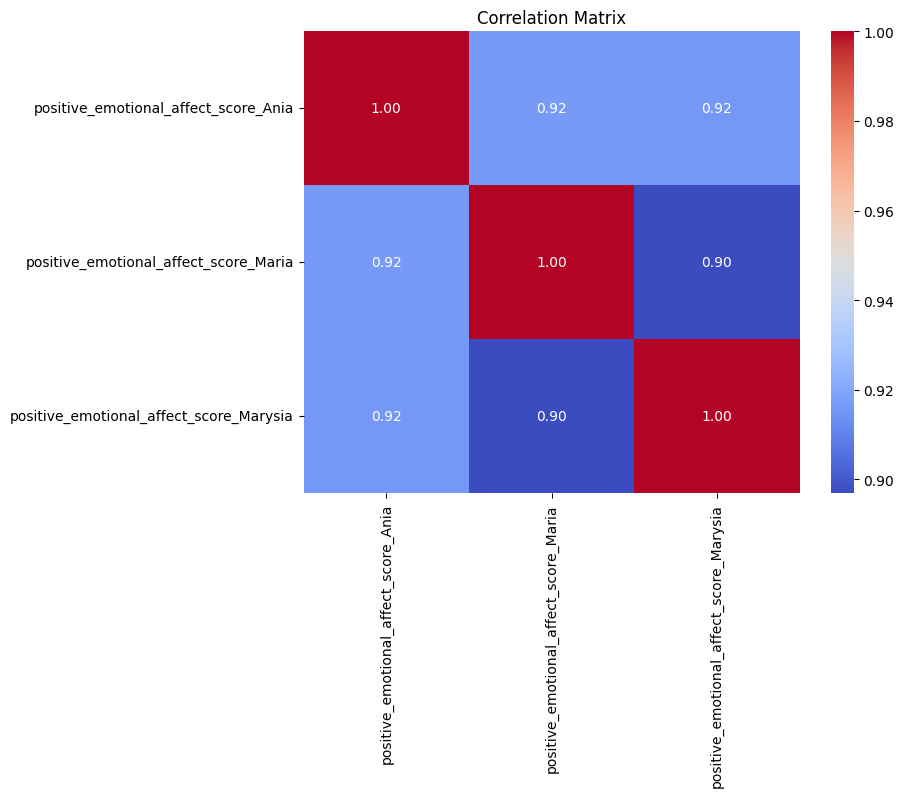

In [14]:
# select only columns that have pos in their name
df_num_pos = data_wide.filter(regex="pos").select_dtypes(include=["number"])

corr=df_num_pos.corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

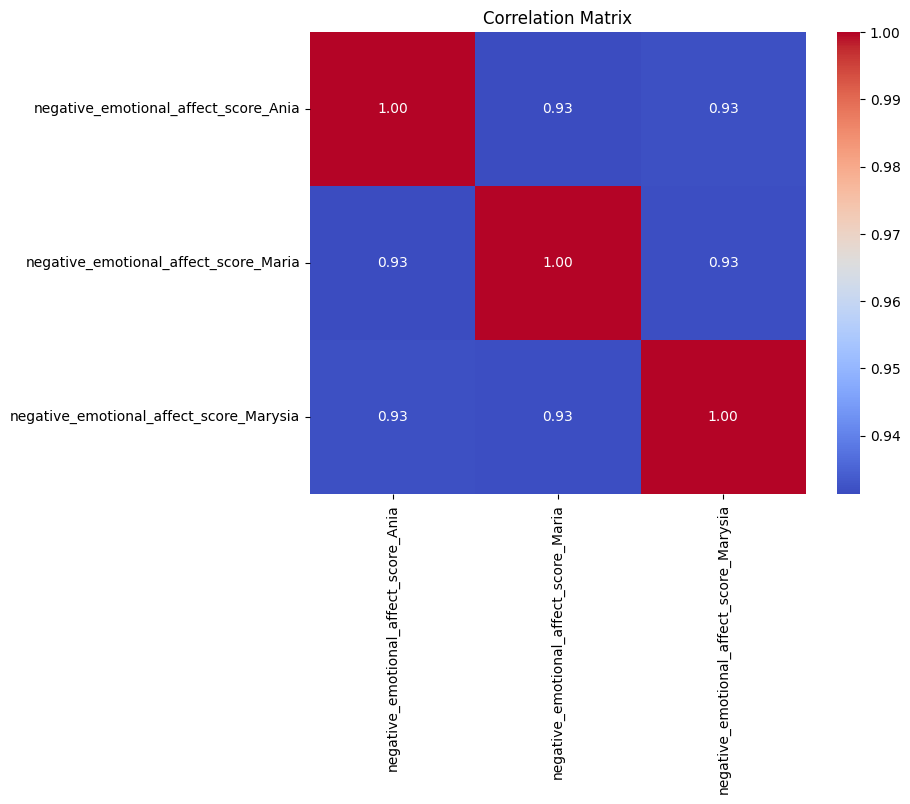

In [15]:
# select only columns that have pos in their name
df_num_neg = data_wide.filter(regex="neg").select_dtypes(include=["number"])

corr=df_num_neg.corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [16]:
# calculate the means
data_wide['intelligence_score_mean'] = data_wide[['intelligence_score_Ania',
                                                  'intelligence_score_Maria', 
                                                  'intelligence_score_Marysia']].mean(axis=1)
data_wide['positive_emotional_affect_score_mean'] = data_wide[['positive_emotional_affect_score_Ania',
                                                                'positive_emotional_affect_score_Maria', 
                                                                'positive_emotional_affect_score_Marysia']].mean(axis=1)
data_wide['negative_emotional_affect_score_mean'] = data_wide[['negative_emotional_affect_score_Ania',
                                                                'negative_emotional_affect_score_Maria', 
                                                                'negative_emotional_affect_score_Marysia']].mean(axis=1)

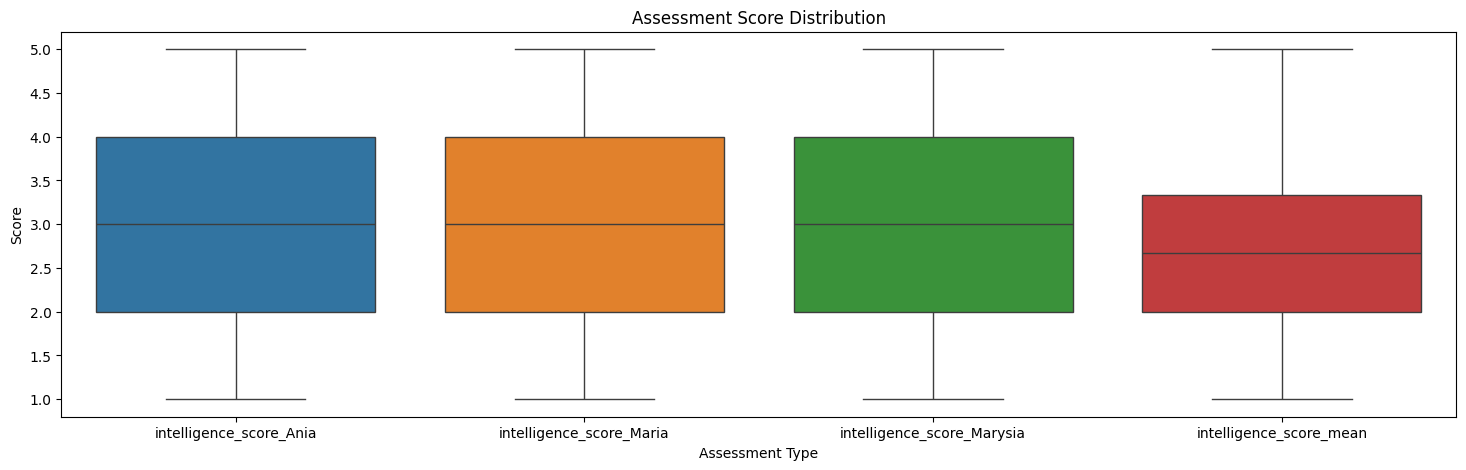

In [17]:
# plot data distribution
plt.figure(figsize=(18, 5))
sns.boxplot(data=data_wide.select_dtypes(include=["number"]).filter(regex="intelligence")),
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

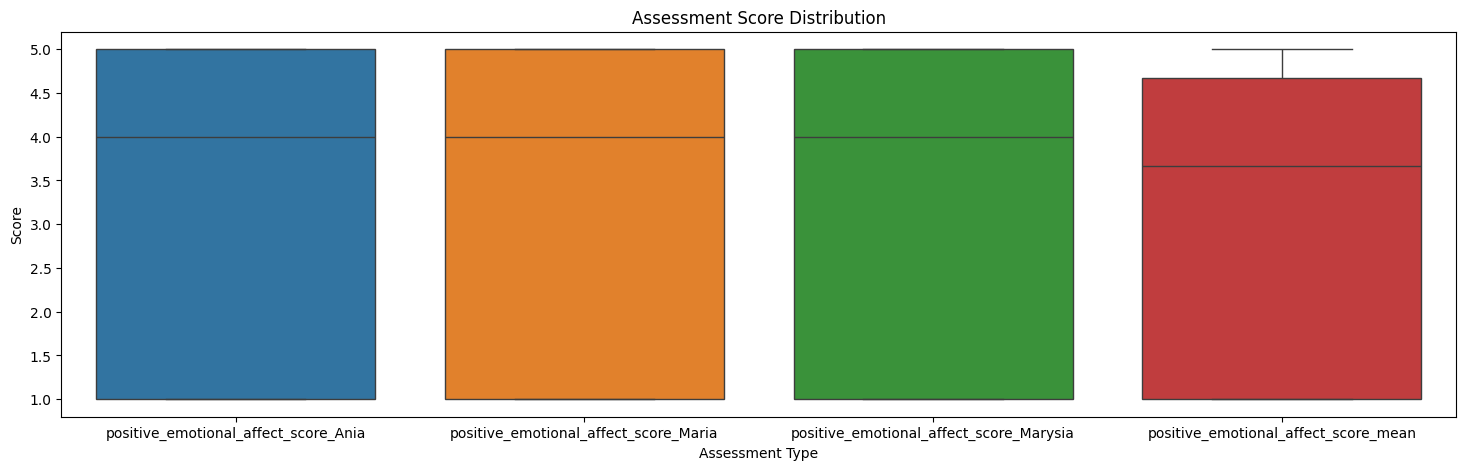

In [18]:
# plot data distribution
plt.figure(figsize=(18, 5))
sns.boxplot(data=data_wide.select_dtypes(include=["number"]).filter(regex="pos")),
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

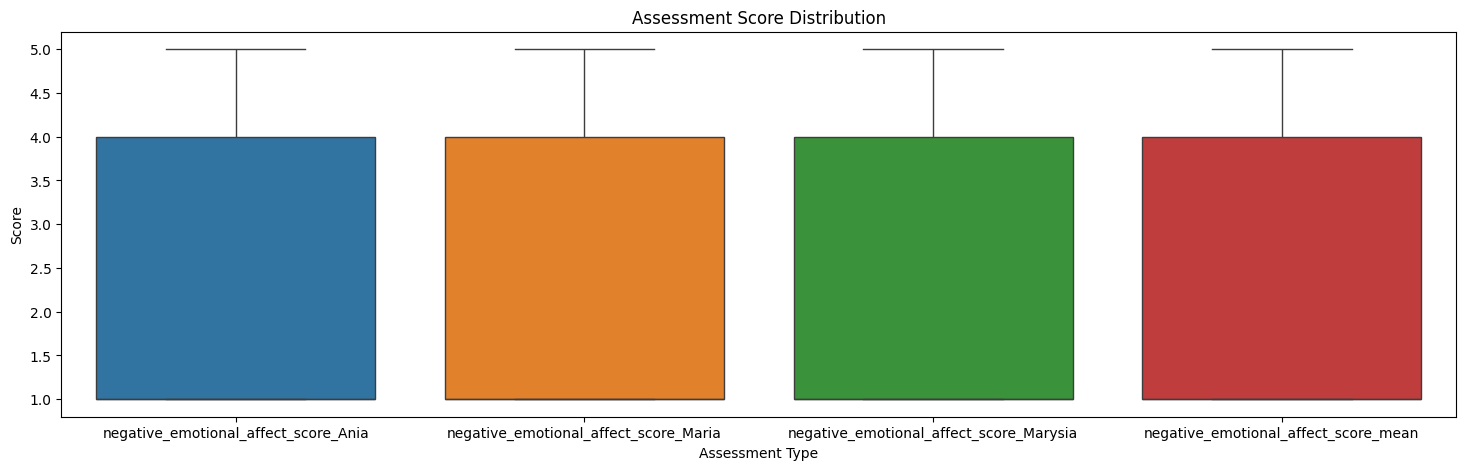

In [19]:
# plot data distribution
plt.figure(figsize=(18, 5))
sns.boxplot(data=data_wide.select_dtypes(include=["number"]).filter(regex="neg")),
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

In [20]:
data_wide.shape

(1323, 16)

In [21]:
data_wide.rename(columns={'intelligence_score_mean': 'mVI',
                        'positive_emotional_affect_score_mean': 'mPEA',
                        'negative_emotional_affect_score_mean': 'mNEA',
                        'riv': 'RIV',
                        'adm': 'ADM'}, inplace=True)

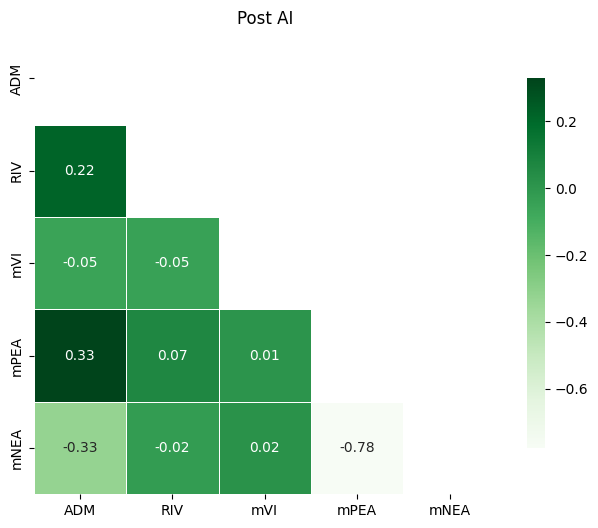

In [22]:
df_num = data_wide[data_wide.post_type=="ai"][['ADM',
                        'RIV',
                        'mVI',
                        'mPEA',
                        'mNEA']].select_dtypes(include=["number"])
corr=df_num.corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="Greens", fmt=".2f",mask=mask, square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Post AI")
plt.show()


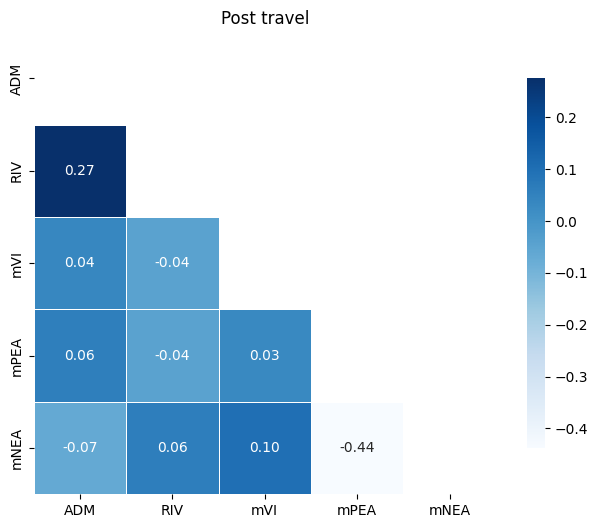

In [23]:
df_num = data_wide[data_wide.post_type=="travel"][['ADM',
                        'RIV',
                        'mVI',
                        'mPEA',
                        'mNEA']].select_dtypes(include=["number"])
corr=df_num.corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f", mask=mask, square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Post travel")
plt.show()

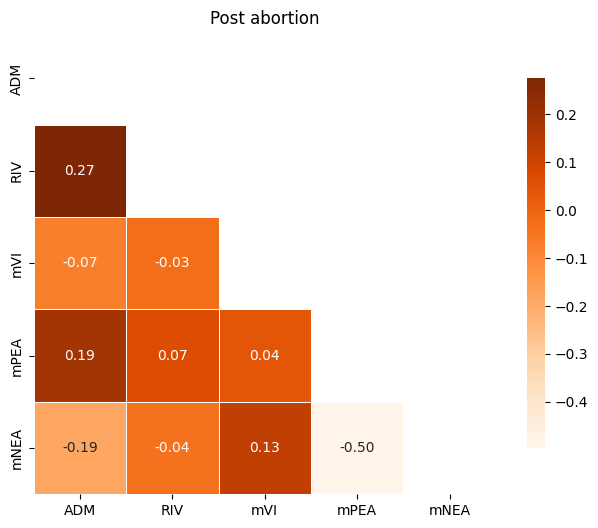

In [24]:
df_num = data_wide[data_wide.post_type=="abortion"][['ADM',
                        'RIV',
                        'mVI',
                        'mPEA',
                        'mNEA']].select_dtypes(include=["number"])
corr=df_num.corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="Oranges", fmt=".2f", mask=mask, square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Post abortion")
plt.show()

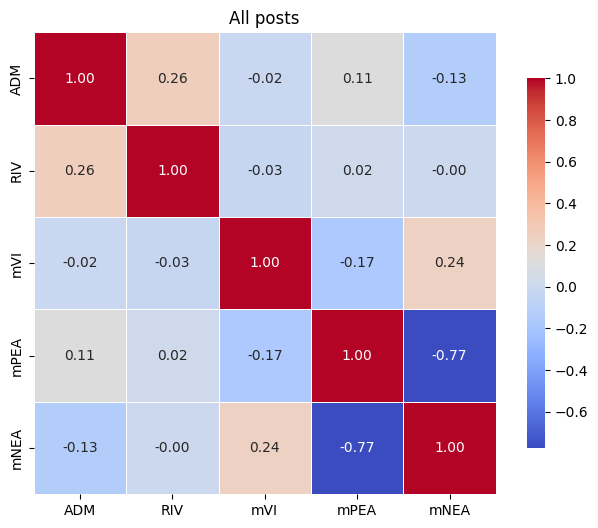

In [25]:
df_num = data_wide[['ADM',
                        'RIV',
                        'mVI',
                        'mPEA',
                        'mNEA']].select_dtypes(include=["number"])
corr=df_num.corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("All posts")
plt.show()

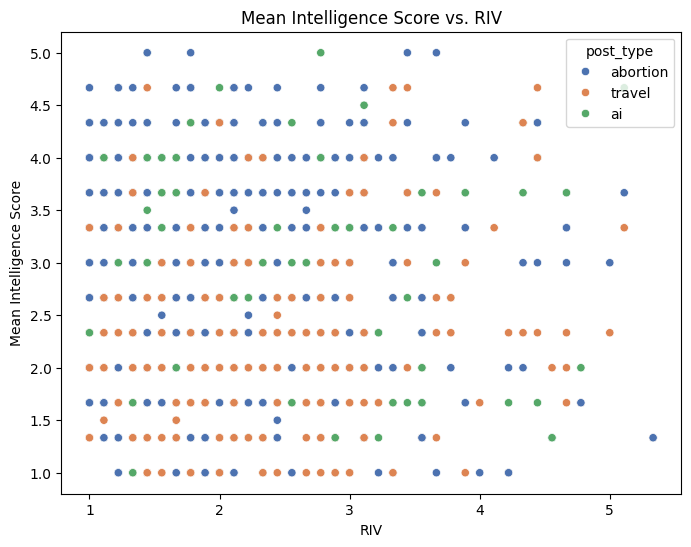

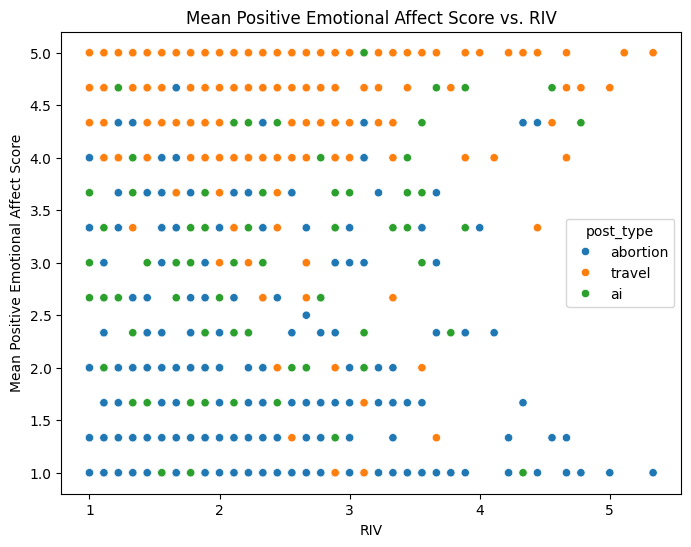

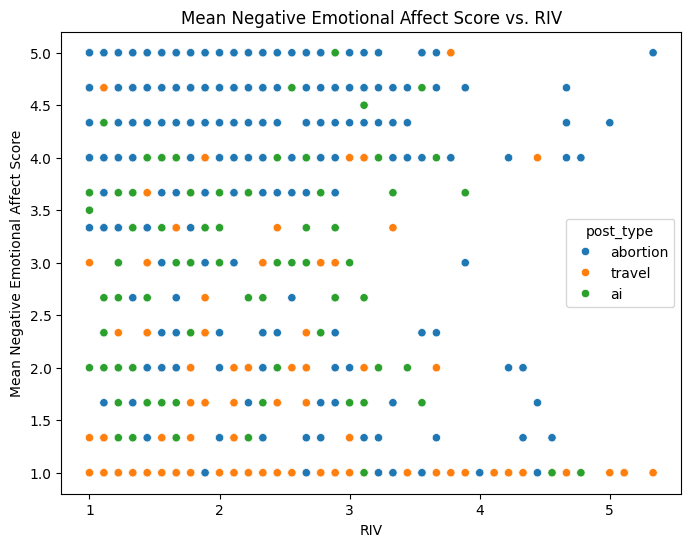

In [26]:
# plot mean intelligence score vs. riv
# add color coding for post_type
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, x='RIV', y='mVI', hue='post_type', palette='deep')
plt.title("Mean Intelligence Score vs. RIV")
plt.xlabel("RIV")
plt.ylabel("Mean Intelligence Score")
plt.show()
# plot mean positive emotional affect score vs. riv
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, x='RIV', y='mPEA', hue='post_type')
plt.title("Mean Positive Emotional Affect Score vs. RIV")
plt.xlabel("RIV")
plt.ylabel("Mean Positive Emotional Affect Score")
plt.show()
# plot mean negative emotional affect score vs. riv
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, x='RIV', y='mNEA', hue='post_type')
plt.title("Mean Negative Emotional Affect Score vs. RIV")
plt.xlabel("RIV")
plt.ylabel("Mean Negative Emotional Affect Score")
plt.show()

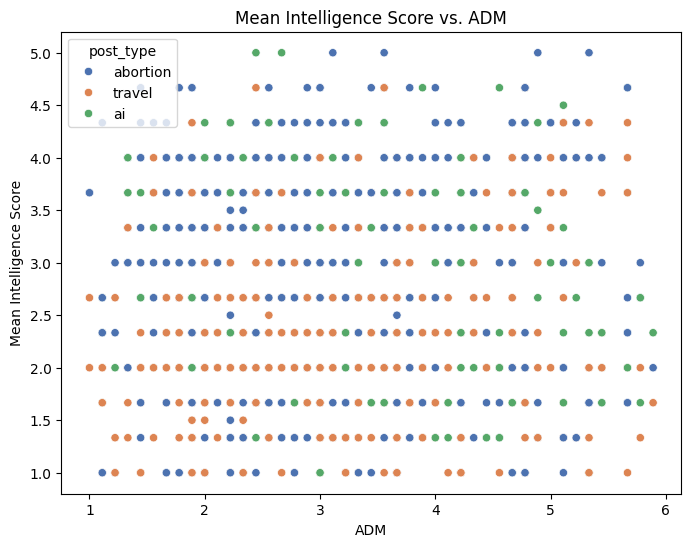

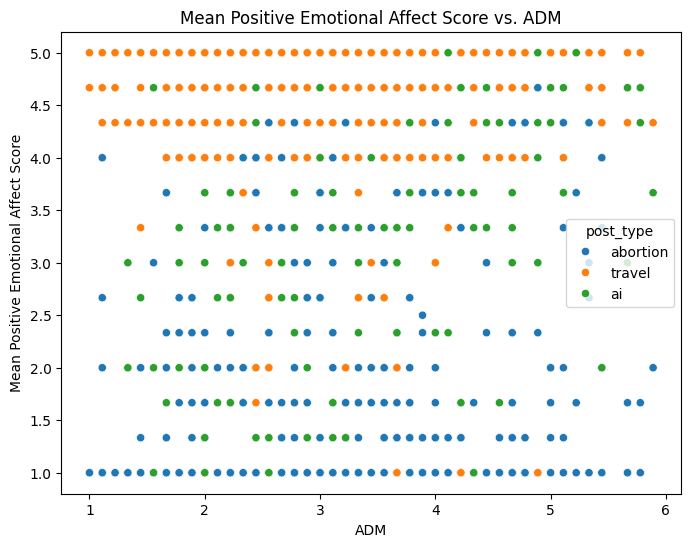

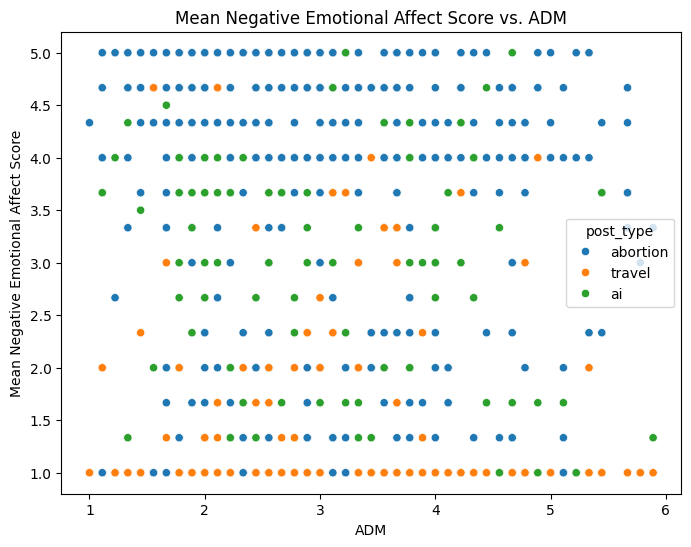

In [27]:
# plot mean intelligence score vs. adm
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, x='ADM', y='mVI', hue='post_type', palette='deep')
plt.title("Mean Intelligence Score vs. ADM")
plt.xlabel("ADM")
plt.ylabel("Mean Intelligence Score")
plt.show()
# plot mean positive emotional affect score vs. adm
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, x='ADM', y='mPEA', hue='post_type')
plt.title("Mean Positive Emotional Affect Score vs. ADM")
plt.xlabel("ADM")
plt.ylabel("Mean Positive Emotional Affect Score")
plt.show()
# plot mean negative emotional affect score vs. adm
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, x='ADM', y='mNEA', hue='post_type')
plt.title("Mean Negative Emotional Affect Score vs. ADM")
plt.xlabel("ADM")
plt.ylabel("Mean Negative Emotional Affect Score")
plt.show()


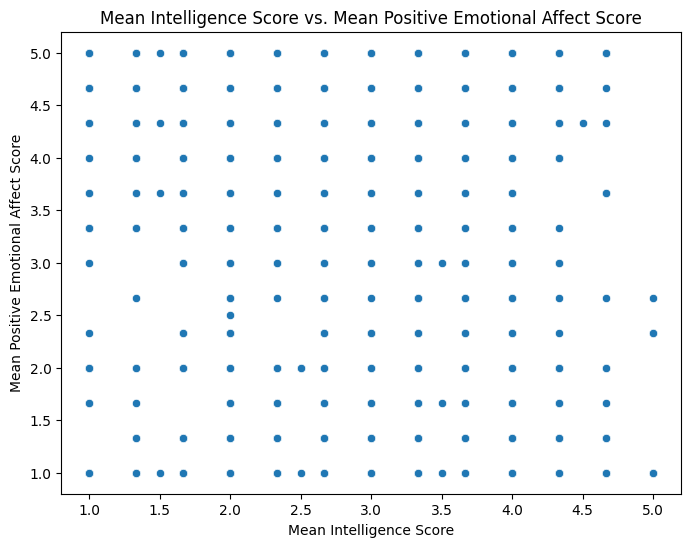

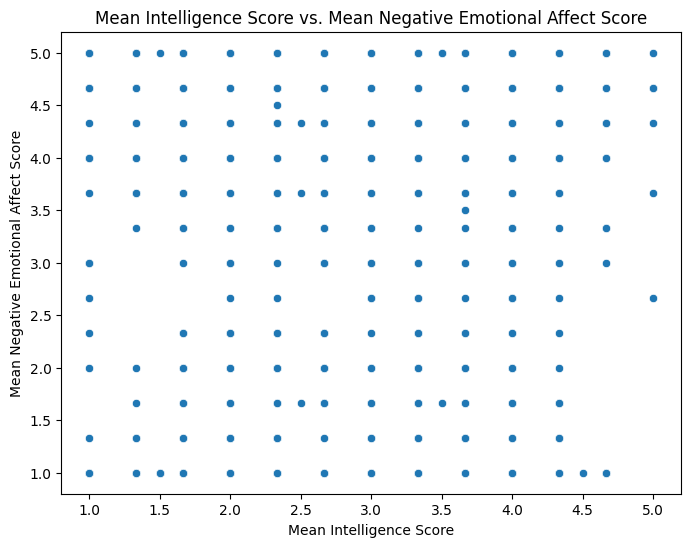

In [28]:
# plot the scatter plot for intelligence score vs positive emotional affect score
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, 
                x='mVI', 
                y='mPEA')
plt.title("Mean Intelligence Score vs. Mean Positive Emotional Affect Score")
plt.xlabel("Mean Intelligence Score")
plt.ylabel("Mean Positive Emotional Affect Score")
plt.show()
# plot the scatter plot for intelligence score vs negative emotional affect score
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_wide, 
                x='mVI', 
                y='mNEA')
plt.title("Mean Intelligence Score vs. Mean Negative Emotional Affect Score")
plt.xlabel("Mean Intelligence Score")
plt.ylabel("Mean Negative Emotional Affect Score")
plt.show()


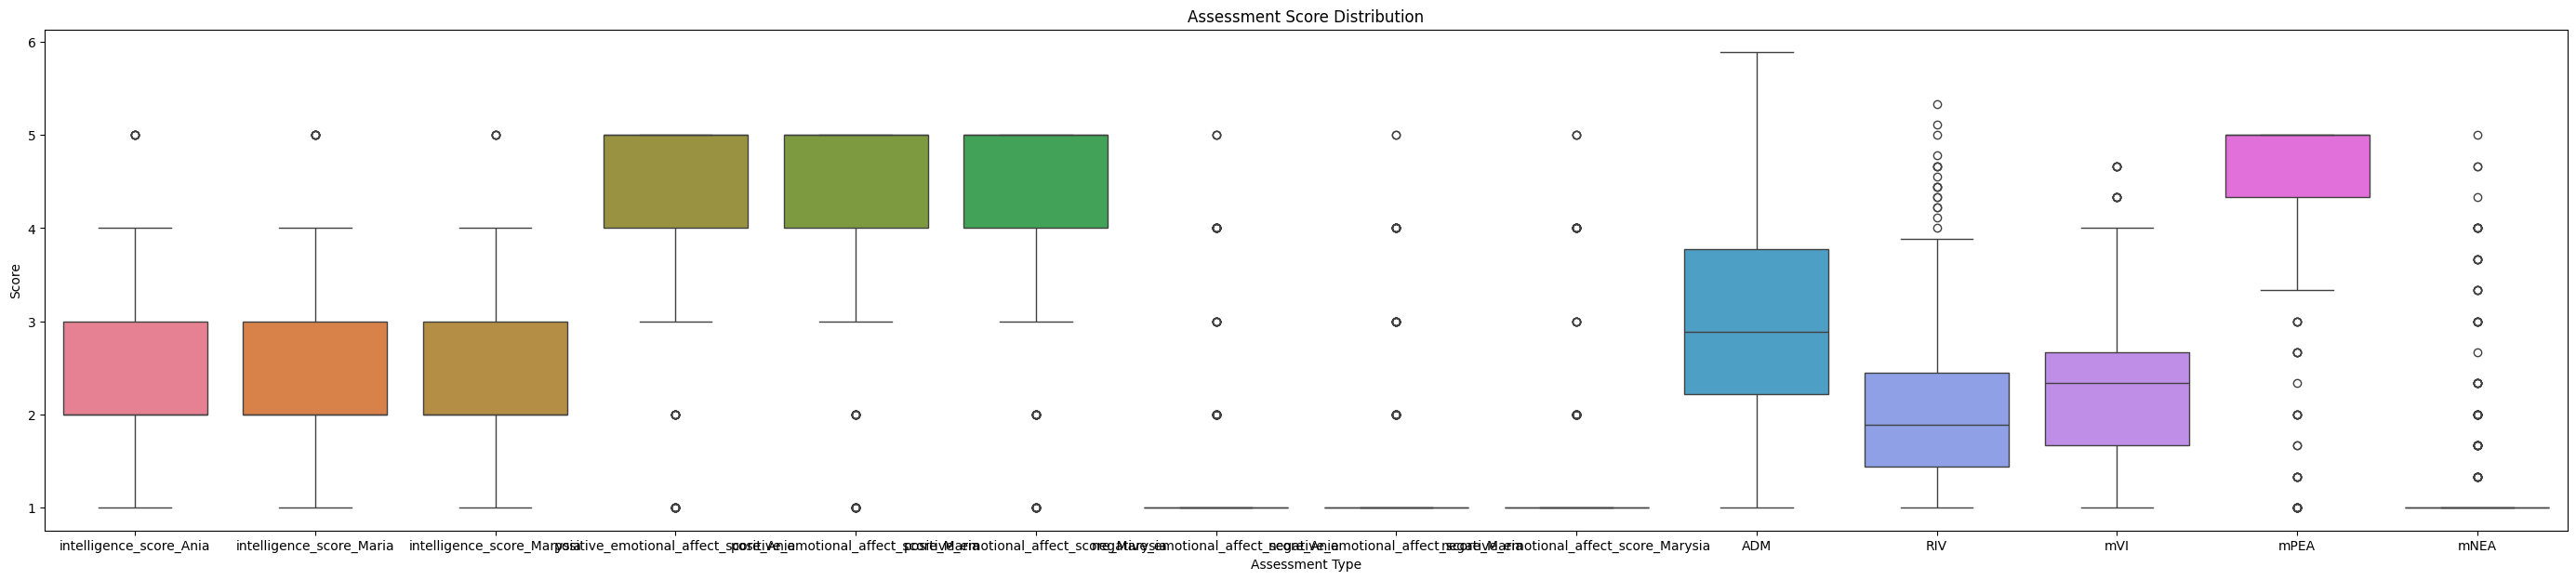

In [38]:
# plot data distribution
plt.figure(figsize=(35, 7))
sns.boxplot(data=data_wide[data_wide.post_type == "travel"].select_dtypes(include=["number"])),
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

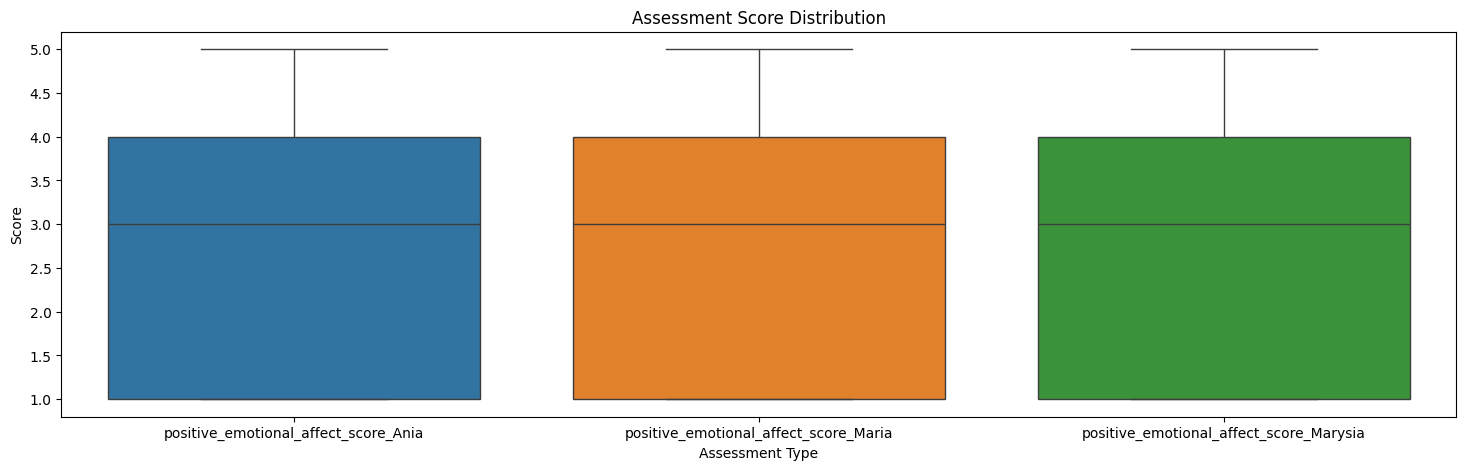

In [34]:
# plot data distribution
plt.figure(figsize=(18, 5))
sns.boxplot(data=data_wide[data_wide.post_type == "ai"].select_dtypes(include=["number"]).filter(regex="pos")),
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

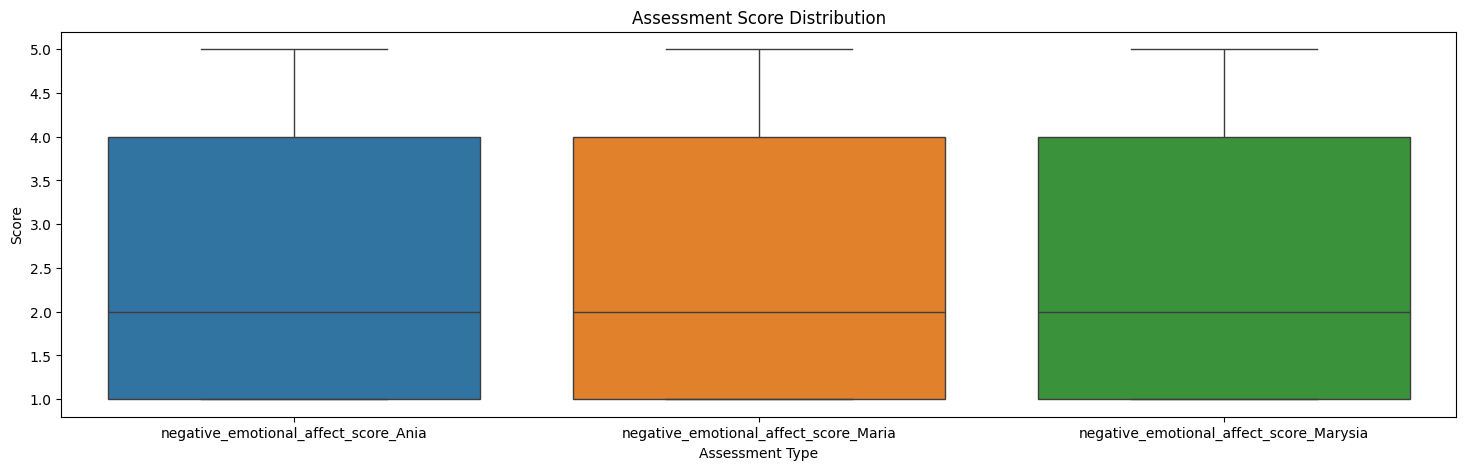

In [35]:
# plot data distribution
plt.figure(figsize=(18, 5))
sns.boxplot(data=data_wide[data_wide.post_type == "ai"].select_dtypes(include=["number"]).filter(regex="neg")),
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()